# Fase 3: Analisis e Interpretacion - YOLO Aforo

Analisis del aforo agrupado por bloque horario, a partir del dataset limpio generado en la Fase 2.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import config

df = pd.read_csv(config.CLEAN_DATASET_PATH)
df.head()

,fecha,dia,hora,clase_objeto,bloque_horario
0,2026-09-17,Jueves,20:45:50,persona,Vespertina
1,2026-09-17,Jueves,20:45:52,persona,Vespertina
2,2026-09-17,Jueves,20:45:55,persona,Vespertina
3,2026-09-17,Jueves,20:45:58,persona,Vespertina
4,2026-09-17,Jueves,20:46:01,persona,Vespertina


## 1. Conteo total de personas por bloque horario

In [2]:
conteo_total = df.groupby('bloque_horario').size().rename('total_personas')
conteo_total

bloque_horario
Vespertina    28
Name: total_personas, dtype: int64

## 2. Promedio de personas por muestra

Cada fila del dataset limpio es una deteccion individual en un instante de muestreo. Agrupamos primero por instante (fecha+hora) contando personas, y luego promediamos esos conteos por bloque horario.

In [3]:
personas_por_muestra = (
    df.groupby(['fecha', 'hora', 'bloque_horario'])
      .size()
      .reset_index(name='personas_en_muestra')
)

promedio_por_bloque = (
    personas_por_muestra.groupby('bloque_horario')['personas_en_muestra']
    .mean()
    .rename('promedio_personas')
)
promedio_por_bloque

bloque_horario
Vespertina    1.076923
Name: promedio_personas, dtype: float64

## 3. Pico maximo de personas detectadas por bloque

In [4]:
pico_por_bloque = (
    personas_por_muestra.groupby('bloque_horario')['personas_en_muestra']
    .max()
    .rename('pico_maximo')
)
pico_por_bloque

bloque_horario
Vespertina    2
Name: pico_maximo, dtype: int64

## 4. Tabla resumen de metricas por bloque horario

In [5]:
resumen = pd.concat([conteo_total, promedio_por_bloque, pico_por_bloque], axis=1)
resumen

,total_personas,promedio_personas,pico_maximo
bloque_horario,,,
Vespertina,28,1.076923,2


## 5. Grafico comparativo

Comparacion visual del total de personas detectadas en cada jornada, para apoyar decisiones de asignacion de personal.

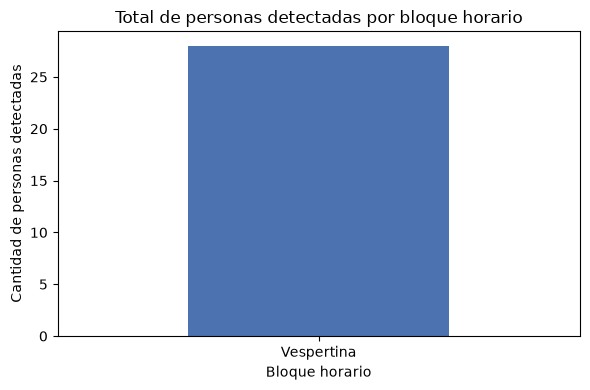

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
conteo_total.plot(kind='bar', ax=ax, color=['#4C72B0', '#DD8452'])
ax.set_title('Total de personas detectadas por bloque horario')
ax.set_xlabel('Bloque horario')
ax.set_ylabel('Cantidad de personas detectadas')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('data/grafico_bloques.png', dpi=150)
plt.show()